# Diffusion Project - FINAL (Kaggle version)

Pick the best sampler setting, regenerate synthetic images, run the multi-seed augmentation sweep.

**Kaggle setup (do this before running):**
1. Right panel > Settings > **Accelerator: GPU (T4 x2 or P100)**, **Internet: On** (needed to download EuroSAT and CLIP).
2. Upload your trained checkpoint: download `latest.pt` from Google Drive (`diffusion_project_checkpoints_v2/`), then Kaggle > Datasets > New Dataset > upload it, and **Add Data** to this notebook. The notebook finds it automatically under `/kaggle/input`.
3. Outputs are written to `/kaggle/working`. They persist only if you click **Save Version > Save & Run All (Commit)**, or download them before the session ends.

## 0. Install (then Runtime > Restart session)

In [1]:
!pip uninstall -y -q torchao
!pip install -q torchgeo peft transformers accelerate matplotlib pandas scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 667.3 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 812.4/812.4 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.2/800.2 kB 41.8 MB/s eta 0:00:00


**Kaggle usually needs no restart after the install cell. If you later see a `peft`/`torchao` ImportError, use Run > Restart & clear outputs, skip the install cell, and run the rest.**

## 1. Setup and Drive

In [2]:
import os, math, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from PIL import Image
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

import glob
assert device == "cuda", "No GPU: enable it in Settings > Accelerator"
print("GPU:", torch.cuda.get_device_name(0))

# Where the trained checkpoint lives (your uploaded Kaggle dataset)
found = glob.glob("/kaggle/input/datasets/ibrahimhachemi/phd-thing/latest.pt", recursive=True)
assert found, "latest.pt not found under /kaggle/input -> add your uploaded dataset via 'Add Data'"
CKPT_PATH = found[0]
print("Using checkpoint:", CKPT_PATH)

# Where we WRITE outputs (synthetic set, result json, plots, optionally continued training)
CKPT_DIR = "/kaggle/working/diffusion_outputs"
os.makedirs(CKPT_DIR, exist_ok=True)
SAVE_CKPT_PATH = f"{CKPT_DIR}/latest.pt"

Device: cuda
GPU: Tesla T4
Using checkpoint: /kaggle/input/datasets/ibrahimhachemi/phd-thing/latest.pt


## 2. Data (EuroSAT RGB, correctly scaled - same as v2)

In [3]:
from torchgeo.datasets import EuroSAT

EUROSAT_ROOT = "/kaggle/temp/eurosat"      # temp disk: large, not saved as output
os.makedirs(EUROSAT_ROOT, exist_ok=True)

def load_split(split):
    return EuroSAT(root=EUROSAT_ROOT, split=split, bands=EuroSAT.BAND_SETS["rgb"], download=True)

raw_train, raw_test = load_split("train"), load_split("test")
CLASS_NAMES = raw_train.classes
NUM_CLASSES = len(CLASS_NAMES)
NULL_CLASS = NUM_CLASSES
IMG_SIZE = 64

def digital_numbers_to_uint8(x, clip_val=3000.0):
    x = torch.clamp(x.float(), min=0, max=clip_val)
    return (x / clip_val * 255.0).round().to(torch.uint8)

def precache(ds):
    imgs, labels = [], []
    for i in range(len(ds)):
        s = ds[i]; imgs.append(digital_numbers_to_uint8(s["image"])); labels.append(int(s["label"]))
    return torch.stack(imgs), torch.tensor(labels)

train_imgs_u8, train_labels_all = precache(raw_train)
test_imgs_u8,  test_labels_all  = precache(raw_test)
print(tuple(train_imgs_u8.shape), tuple(test_imgs_u8.shape), "range", train_imgs_u8.min().item(), "-", train_imgs_u8.max().item())

class EuroSATDiffusionDataset(torch.utils.data.Dataset):
    def __init__(self, imgs_u8, labels): self.imgs, self.labels = imgs_u8, labels
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return self.imgs[i].float() / 255.0 * 2 - 1, int(self.labels[i])

train_diff_ds = EuroSATDiffusionDataset(train_imgs_u8, train_labels_all)

eurosat-train.txt: 100%|██████████| 306k/306k [00:00<00:00, 24.9MB/s]
EuroSATallBands.zip: 100%|██████████| 1.93G/1.93G [00:32<00:00, 64.1MB/s]
eurosat-test.txt: 100%|██████████| 102k/102k [00:00<00:00, 43.9MB/s]


(16200, 3, 64, 64) (5400, 3, 64, 64) range 0 - 255


## 3. Model + diffusion code (identical architecture to training; sampler now clips x0)

In [4]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        emb = math.log(10000) / (half - 1)
        emb = torch.exp(torch.arange(half, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        return torch.cat((emb.sin(), emb.cos()), dim=-1)

class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch); self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb_proj = nn.Linear(emb_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch); self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class SelfAttention(nn.Module):
    def __init__(self, ch, num_heads=4):
        super().__init__()
        self.num_heads = num_heads; self.norm = nn.GroupNorm(8, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1); self.proj = nn.Conv2d(ch, ch, 1)
    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).chunk(3, dim=1)
        q = q.reshape(b, self.num_heads, c // self.num_heads, h * w)
        k = k.reshape(b, self.num_heads, c // self.num_heads, h * w)
        v = v.reshape(b, self.num_heads, c // self.num_heads, h * w)
        attn = torch.softmax((q.transpose(-1, -2) @ k) / math.sqrt(c // self.num_heads), dim=-1)
        return x + self.proj((v @ attn.transpose(-1, -2)).reshape(b, c, h, w))

class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.op = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x): return self.op(x)

class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__(); self.op = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x): return self.op(F.interpolate(x, scale_factor=2, mode="nearest"))

class UNet(nn.Module):
    def __init__(self, in_ch=3, base_ch=64, ch_mults=(1, 2, 2, 2), num_res_blocks=2,
                 attn_resolutions=(16, 8), num_classes=10, img_size=64):
        super().__init__()
        emb_dim = base_ch * 4
        self.time_mlp = nn.Sequential(SinusoidalPosEmb(base_ch), nn.Linear(base_ch, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.label_emb = nn.Embedding(num_classes + 1, emb_dim)
        self.init_conv = nn.Conv2d(in_ch, base_ch, 3, padding=1)
        self.down_blocks = nn.ModuleList(); ch = base_ch; res = img_size; track = [ch]
        for i, mult in enumerate(ch_mults):
            out_ch = base_ch * mult
            for _ in range(num_res_blocks):
                blk = nn.ModuleList([ResidualBlock(ch, out_ch, emb_dim)])
                if res in attn_resolutions: blk.append(SelfAttention(out_ch))
                self.down_blocks.append(blk); ch = out_ch; track.append(ch)
            if i != len(ch_mults) - 1:
                self.down_blocks.append(nn.ModuleList([Downsample(ch)])); track.append(ch); res //= 2
        self.mid_block1 = ResidualBlock(ch, ch, emb_dim); self.mid_attn = SelfAttention(ch); self.mid_block2 = ResidualBlock(ch, ch, emb_dim)
        self.up_blocks = nn.ModuleList()
        for i, mult in reversed(list(enumerate(ch_mults))):
            out_ch = base_ch * mult
            for _ in range(num_res_blocks + 1):
                skip_ch = track.pop()
                blk = nn.ModuleList([ResidualBlock(ch + skip_ch, out_ch, emb_dim)])
                if res in attn_resolutions: blk.append(SelfAttention(out_ch))
                self.up_blocks.append(blk); ch = out_ch
            if i != 0:
                self.up_blocks.append(nn.ModuleList([Upsample(ch)])); res *= 2
        self.out_norm = nn.GroupNorm(8, ch); self.out_conv = nn.Conv2d(ch, in_ch, 3, padding=1)
    def forward(self, x, t, y):
        emb = self.time_mlp(t) + self.label_emb(y)
        h = self.init_conv(x); skips = [h]
        for blk in self.down_blocks:
            if isinstance(blk[0], Downsample): h = blk[0](h)
            else:
                h = blk[0](h, emb)
                if len(blk) > 1: h = blk[1](h)
            skips.append(h)
        h = self.mid_block2(self.mid_attn(self.mid_block1(h, emb)), emb)
        for blk in self.up_blocks:
            if isinstance(blk[0], Upsample): h = blk[0](h)
            else:
                h = blk[0](torch.cat([h, skips.pop()], dim=1), emb)
                if len(blk) > 1: h = blk[1](h)
        return self.out_conv(F.silu(self.out_norm(h)))

def build_unet():
    return UNet(3, 64, (1, 2, 2, 2), 2, (16, 8), NUM_CLASSES, IMG_SIZE).to(device)

In [5]:
def cosine_beta_schedule(T, s=0.008):
    t = torch.linspace(0, T, T + 1) / T
    ac = torch.cos((t + s) / (1 + s) * math.pi * 0.5) ** 2
    ac = ac / ac[0]
    return torch.clip(1 - (ac[1:] / ac[:-1]), 1e-5, 0.999)

class GaussianDiffusion:
    def __init__(self, timesteps=1000, device="cuda"):
        self.T = timesteps
        self.betas = cosine_beta_schedule(timesteps).to(device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0), value=1.0)
        self.sqrt_ac = torch.sqrt(self.alphas_cumprod)
        self.sqrt_omac = torch.sqrt(1.0 - self.alphas_cumprod)
        self.posterior_variance = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
    def _ex(self, a, t, shape):
        return a.gather(-1, t).reshape(t.shape[0], *((1,) * (len(shape) - 1)))
    def q_sample(self, x0, t, noise):
        return self._ex(self.sqrt_ac, t, x0.shape) * x0 + self._ex(self.sqrt_omac, t, x0.shape) * noise
    def p_losses(self, model, x0, t, y):
        noise = torch.randn_like(x0)
        return F.mse_loss(model(self.q_sample(x0, t, noise), t, y), noise)

    def _cfg_eps(self, model, x, t, y, w):
        if w == 1.0:
            return model(x, t, y)
        e_c = model(x, t, y); e_u = model(x, t, torch.full_like(y, NULL_CLASS))
        return e_u + w * (e_c - e_u)

    @torch.no_grad()
    def p_sample_loop(self, model, shape, y, guidance_scale=3.0, clip_x0=True):
        # DDPM ancestral sampling. With clip_x0, mean is computed from the clipped x0 estimate (standard practice).
        x = torch.randn(shape, device=y.device); b = shape[0]
        for i in reversed(range(self.T)):
            t = torch.full((b,), i, device=y.device, dtype=torch.long)
            eps = self._cfg_eps(model, x, t, y, guidance_scale)
            ab = self._ex(self.alphas_cumprod, t, x.shape)
            if clip_x0:
                x0 = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-1, 1)
                abp = self._ex(self.alphas_cumprod_prev, t, x.shape)
                beta = self._ex(self.betas, t, x.shape); alpha = self._ex(self.alphas, t, x.shape)
                mean = (abp.sqrt() * beta / (1 - ab)) * x0 + (alpha.sqrt() * (1 - abp) / (1 - ab)) * x
            else:
                alpha = self._ex(self.alphas, t, x.shape); beta = self._ex(self.betas, t, x.shape)
                mean = (1 / alpha.sqrt()) * (x - (beta / (1 - ab).sqrt()) * eps)
            if i > 0:
                x = mean + self._ex(self.posterior_variance, t, x.shape).sqrt() * torch.randn_like(x)
            else:
                x = mean
        return x

    @torch.no_grad()
    def ddim_sample_loop(self, model, shape, y, steps=50, guidance_scale=3.0, clip_x0=True):
        times = torch.linspace(self.T - 1, 0, steps, dtype=torch.long, device=y.device)
        x = torch.randn(shape, device=y.device); b = shape[0]
        for idx in range(len(times)):
            t = torch.full((b,), times[idx].item(), device=y.device, dtype=torch.long)
            eps = self._cfg_eps(model, x, t, y, guidance_scale)
            ab = self._ex(self.alphas_cumprod, t, x.shape)
            x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
            if clip_x0:
                x0 = x0.clamp(-1, 1); eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()
            if idx == len(times) - 1:
                x = x0
            else:
                tp = torch.full((b,), times[idx + 1].item(), device=y.device, dtype=torch.long)
                abp = self._ex(self.alphas_cumprod, tp, x.shape)
                x = abp.sqrt() * x0 + (1 - abp).sqrt() * eps
        return x

diffusion = GaussianDiffusion(1000, device)
print("diffusion ready")

diffusion ready


## 4. Load your trained weights from Drive (raw AND EMA)

In [6]:
ckpt = torch.load(CKPT_PATH, map_location=device)
print("Checkpoint step:", ckpt["step"])

ema_model = build_unet();  ema_model.load_state_dict(ckpt["ema"]);   ema_model.eval()
raw_model = build_unet();  raw_model.load_state_dict(ckpt["model"]); raw_model.eval()
print("Loaded EMA and raw weights. Params:", sum(p.numel() for p in ema_model.parameters()))

Checkpoint step: 10000
Loaded EMA and raw weights. Params: 9286403


## 5. Diagnostics - read these figures BEFORE generating anything

**Figure 1 (model check):** a real image, the same image noised to t=500, and the model's one-shot recovery.
**Figure 2 (sampler check):** same seed, same classes, different weights/samplers.

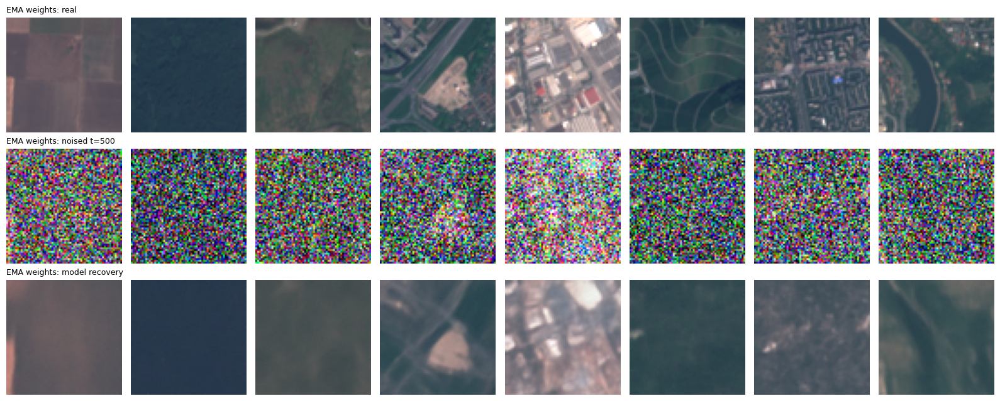

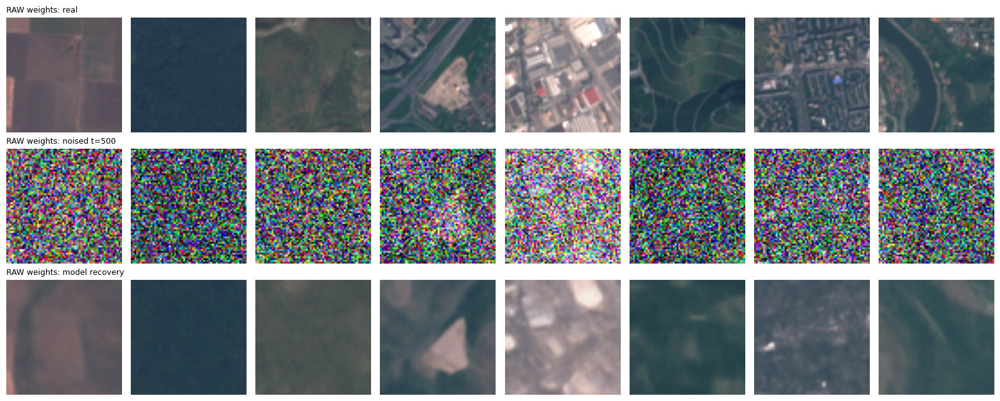

In [7]:
def to_img(t):
    return ((t.clamp(-1, 1) + 1) / 2).permute(1, 2, 0).cpu().numpy()

@torch.no_grad()
def recon_test(model, n=8, t_level=500):
    step = len(train_diff_ds) // n
    items = [train_diff_ds[i * step] for i in range(n)]
    x0 = torch.stack([a for a, _ in items]).to(device); y = torch.tensor([b for _, b in items]).to(device)
    t = torch.full((n,), t_level, device=device, dtype=torch.long)
    xt = diffusion.q_sample(x0, t, torch.randn_like(x0))
    ab = diffusion._ex(diffusion.alphas_cumprod, t, x0.shape)
    x0_hat = (xt - (1 - ab).sqrt() * model(xt, t, y)) / ab.sqrt()
    return x0, xt, x0_hat

for name, m in [("EMA weights", ema_model), ("RAW weights", raw_model)]:
    x0, xt, x0h = recon_test(m)
    fig, ax = plt.subplots(3, 8, figsize=(16, 6.5))
    for r, (lbl, im) in enumerate([("real", x0), ("noised t=500", xt), ("model recovery", x0h)]):
        for c in range(8):
            ax[r, c].imshow(to_img(im[c])); ax[r, c].axis("off")
        ax[r, 0].set_title(f"{name}: {lbl}", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

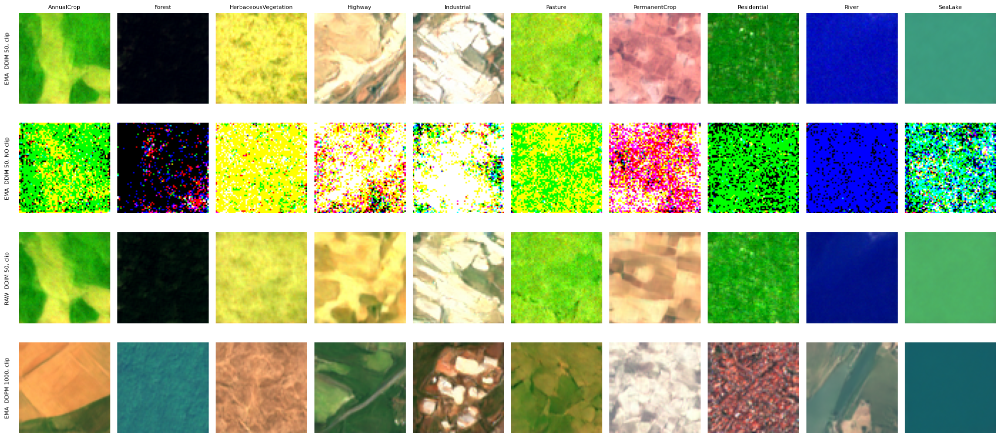

In [8]:
y = torch.arange(NUM_CLASSES, device=device)
shape = (NUM_CLASSES, 3, IMG_SIZE, IMG_SIZE)
runs = [
    ("EMA  DDIM 50, clip",    lambda: diffusion.ddim_sample_loop(ema_model, shape, y, 50, 3.0, True)),
    ("EMA  DDIM 50, NO clip", lambda: diffusion.ddim_sample_loop(ema_model, shape, y, 50, 3.0, False)),
    ("RAW  DDIM 50, clip",    lambda: diffusion.ddim_sample_loop(raw_model, shape, y, 50, 3.0, True)),
    ("EMA  DDPM 1000, clip",  lambda: diffusion.p_sample_loop(ema_model, shape, y, 3.0, True)),
]
fig, ax = plt.subplots(len(runs), NUM_CLASSES, figsize=(20, 2.3 * len(runs)))
for r, (name, fn) in enumerate(runs):
    torch.manual_seed(0); out = fn()
    for c in range(NUM_CLASSES):
        ax[r, c].imshow(to_img(out[c])); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(CLASS_NAMES[c], fontsize=8)
    ax[r, 0].text(-0.1, 0.5, name, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

### GATE - how to read it
| What you see | Meaning | Action |
|---|---|---|
| Recovery matches the real image; some sampler row looks like satellite tiles | Model is fine; pick that row | Set `CHOSEN` below to match, generate |
| Recovery is good, **all** sampler rows are noise | Generation from pure noise fails | Send me the figures; do not continue |
| Recovery is bad for EMA but good for RAW | EMA was not accumulated correctly | Set `CHOSEN_MODEL = raw_model` |
| Recovery bad for both | Model under-trained / broken | Run the optional continue-training cell |

## 5b. Pick sampler settings with a quality check (not by eye alone)

Two cheap proxies, computed with CLIP features:
- **Class fidelity:** a linear probe trained on REAL images predicts the class of each synthetic image. Higher = images look like their intended class. Compare against the probe's accuracy on real test images (the ceiling).
- **Diversity:** 1 - mean cosine similarity between images of the same class. Compare with the real-image value. Very high guidance raises fidelity but kills diversity and distorts colors, so you want BOTH close to the real numbers.

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

REAL reference -> probe accuracy on real test: 92.1% | diversity: 0.104
{'config': 'DDIM50  w=1.0', 'class_fidelity_%': 28.5, 'diversity': 0.115, 'seconds': 39}
{'config': 'DDIM100 w=1.5', 'class_fidelity_%': 36.0, 'diversity': 0.11, 'seconds': 147}
{'config': 'DDIM100 w=2.0', 'class_fidelity_%': 43.5, 'diversity': 0.108, 'seconds': 148}
{'config': 'DDIM100 w=3.0', 'class_fidelity_%': 46.5, 'diversity': 0.106, 'seconds': 148}
{'config': 'DDPM1000 w=1.5', 'class_fidelity_%': 51.0, 'diversity': 0.128, 'seconds': 1479}
        config  class_fidelity_%  diversity  seconds
 DDIM50  w=1.0              28.5      0.115       39
 DDIM100 w=1.5              36.0      0.110      147
 DDIM100 w=2.0              43.5      0.108      148
 DDIM100 w=3.0              46.5      0.106      148
DDPM1000 w=1.5              51.0      0.128     1479
(real reference: diversity 0.104)


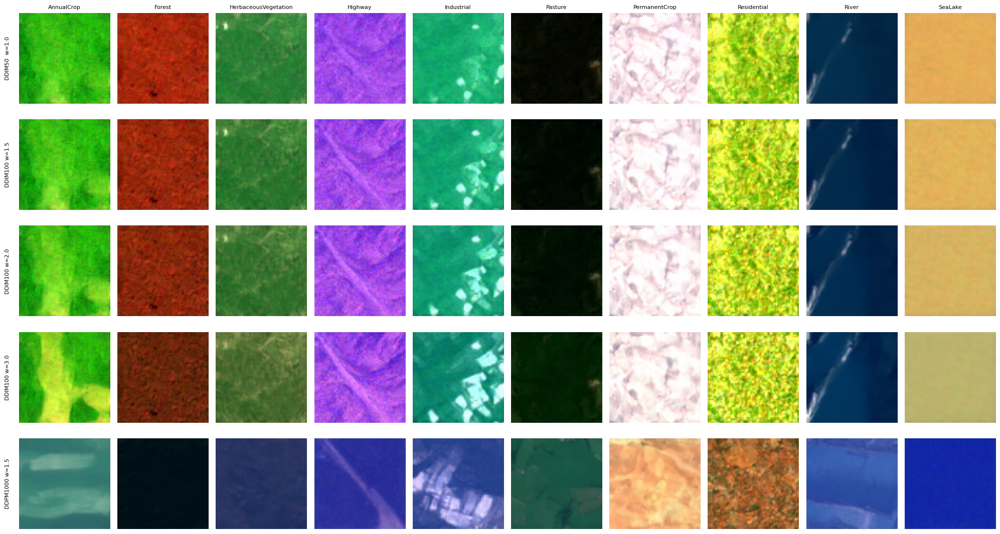

In [9]:
from transformers import CLIPModel, CLIPProcessor
from sklearn.linear_model import LogisticRegression
import pandas as pd

MODEL_NAME = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(MODEL_NAME)
probe_clip = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()

def u8_to_pil(t): return Image.fromarray(t.permute(1, 2, 0).numpy())
def synth_to_pil(t): return Image.fromarray(((t.clamp(-1, 1) + 1) / 2 * 255).byte().permute(1, 2, 0).numpy())

@torch.no_grad()
def clip_embed(pils, bs=128):
    out = []
    for i in range(0, len(pils), bs):
        px = clip_processor(images=pils[i:i + bs], return_tensors="pt")["pixel_values"].to(device)
        f = probe_clip.get_image_features(pixel_values=px)
        f = f if torch.is_tensor(f) else f.pooler_output
        out.append(F.normalize(f, dim=-1).cpu())
    return torch.cat(out).numpy()

def diversity(X, y):
    vals = []
    for c in range(NUM_CLASSES):
        Xc = X[y == c]; S = Xc @ Xc.T; n = len(Xc)
        vals.append(1 - (S.sum() - np.trace(S)) / (n * (n - 1)))
    return float(np.mean(vals))

ytr_all = train_labels_all.numpy()
tr_idx = np.concatenate([np.where(ytr_all == c)[0][:200] for c in range(NUM_CLASSES)])
Xtr = clip_embed([u8_to_pil(train_imgs_u8[i]) for i in tr_idx]); ytr = ytr_all[tr_idx]
te_idx = np.random.default_rng(0).choice(len(test_imgs_u8), 1000, replace=False)
Xte = clip_embed([u8_to_pil(test_imgs_u8[i]) for i in te_idx]); yte = test_labels_all.numpy()[te_idx]
probe = LogisticRegression(max_iter=3000, C=10).fit(Xtr, ytr)
real_div = diversity(Xtr, ytr)
print(f"REAL reference -> probe accuracy on real test: {probe.score(Xte, yte)*100:.1f}% | diversity: {real_div:.3f}")

USE_FP16 = False   # True ~2x faster sampling, but image quality with fp16 is not validated

@torch.no_grad()
def gen(model, per_class, sampler, steps, w, batch=200, verbose=False):
    # all classes batched together -> far fewer sequential sampler loops
    ys = torch.arange(NUM_CLASSES, device=device).repeat_interleave(per_class)
    imgs = []
    for i in range(0, len(ys), batch):
        y = ys[i:i + batch]
        sh = (len(y), 3, IMG_SIZE, IMG_SIZE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
            x = diffusion.ddim_sample_loop(model, sh, y, steps, w, True) if sampler == "ddim" \
                else diffusion.p_sample_loop(model, sh, y, w, True)
        imgs.append(x.float().cpu())
        if verbose: print(f"{min(i + batch, len(ys))}/{len(ys)}")
    return torch.cat(imgs), ys.cpu()

import time
CONFIGS = [
    ("DDIM50  w=1.0", "ddim", 50, 1.0),
    ("DDIM100 w=1.5", "ddim", 100, 1.5),
    ("DDIM100 w=2.0", "ddim", 100, 2.0),
    ("DDIM100 w=3.0", "ddim", 100, 3.0),
    ("DDPM1000 w=1.5", "ddpm", 1000, 1.5),   # slowest; delete this line to skip DDPM
]
N_EVAL = 20   # per class
rows, grids = [], {}
for name, sampler, steps, w in CONFIGS:
    t0 = time.time(); torch.manual_seed(0)
    imgs, labs = gen(ema_model, N_EVAL, sampler, steps, w)
    X = clip_embed([synth_to_pil(t) for t in imgs]); y = labs.numpy()
    rows.append({"config": name, "class_fidelity_%": round(probe.score(X, y) * 100, 1), "diversity": round(diversity(X, y), 3), "seconds": round(time.time() - t0)})
    grids[name] = imgs[[int((labs == c).nonzero(as_tuple=True)[0][0]) for c in range(NUM_CLASSES)]]
    print(rows[-1])
print(pd.DataFrame(rows).to_string(index=False))
print(f"(real reference: diversity {real_div:.3f})")

fig, ax = plt.subplots(len(CONFIGS), NUM_CLASSES, figsize=(20, 2.2 * len(CONFIGS)))
for r, (name, *_) in enumerate(CONFIGS):
    for c in range(NUM_CLASSES):
        ax[r, c].imshow(to_img(grids[name][c])); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(CLASS_NAMES[c], fontsize=8)
    ax[r, 0].text(-0.1, 0.5, name, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Generate the final synthetic set

Set the three variables from the 5b table + grid: choose the setting whose fidelity is high AND whose diversity is closest to the real value, with natural-looking colors.
DDPM-1000 is the most faithful but ~10x slower than DDIM-100; for 2000 images expect on the order of an hour on a T4 (run it in the background of your session, checkpointed to Drive).

200/2000
400/2000
600/2000
800/2000
1000/2000
1200/2000
1400/2000
1600/2000
1800/2000
2000/2000
torch.Size([2000, 3, 64, 64]) range -1.0 1.0


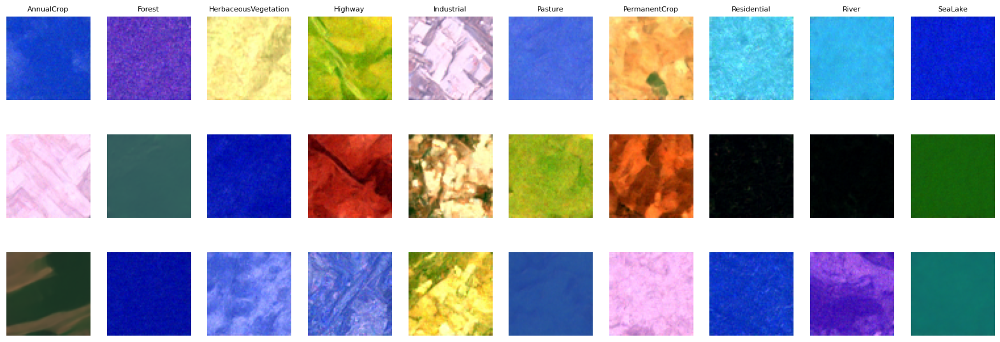

In [10]:
# >>> EDIT after reading the 5b table/grid <<<
SAMPLER, STEPS, GUIDANCE = "ddim", 100, 1.5
PER_CLASS_FINAL = 200

synth_images, synth_labels = gen(ema_model, PER_CLASS_FINAL, SAMPLER, STEPS, GUIDANCE, verbose=True)
torch.save({"images": synth_images, "labels": synth_labels, "cfg": (SAMPLER, STEPS, GUIDANCE)}, f"{CKPT_DIR}/synthetic_dataset_v4.pt")
print(synth_images.shape, "range", synth_images.min().item(), synth_images.max().item())

fig, ax = plt.subplots(3, NUM_CLASSES, figsize=(20, 6.8))
for c in range(NUM_CLASSES):
    idx = (synth_labels == c).nonzero(as_tuple=True)[0][:3]
    for r, j in enumerate(idx):
        ax[r, c].imshow(to_img(synth_images[j])); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(CLASS_NAMES[c], fontsize=8)
plt.show()

## 7. Augmentation sweep, multiple seeds

Previous sweep used one seed and over-saturated synthetic images, so its numbers are not reportable. Now: 3 seeds
(different k-shot draws AND training seeds), mean +/- std. Everything is resumable via a JSON file on Drive.
Start with `SEEDS = [1]` if you want a quick first look, then add seeds.

In [11]:
from peft import LoraConfig, get_peft_model

def build_lora_vision_model():
    m = CLIPModel.from_pretrained(MODEL_NAME).to(device)
    for p in m.parameters(): p.requires_grad = False
    m.vision_model = get_peft_model(m.vision_model, LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"], lora_dropout=0.05, bias="none"))
    return m

class ClipLoraClassifier(nn.Module):
    def __init__(self, clip_m, dim, n):
        super().__init__(); self.clip = clip_m; self.head = nn.Linear(dim, n)
    def forward(self, px):
        v = self.clip.visual_projection(self.clip.vision_model(pixel_values=px).pooler_output)
        return self.head(F.normalize(v, dim=-1))

class PilDS(torch.utils.data.Dataset):
    def __init__(self, imgs_u8, labels): self.imgs, self.labels = imgs_u8, labels
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return Image.fromarray(self.imgs[i].permute(1, 2, 0).numpy()), int(self.labels[i])

clip_train_ds, clip_test_ds = PilDS(train_imgs_u8, train_labels_all), PilDS(test_imgs_u8, test_labels_all)

def k_shot_subset(k, seed):
    rng = random.Random(seed); by = {c: [] for c in range(NUM_CLASSES)}
    for i, l in enumerate(train_labels_all.tolist()): by[l].append(i)
    ch = []
    for c, idxs in by.items():
        rng.shuffle(idxs); ch.extend(idxs[:k])
    return Subset(clip_train_ds, ch)

class AugDS(torch.utils.data.Dataset):
    def __init__(self, real, m):
        self.real, self.syn = real, []
        if m > 0:
            for c in range(NUM_CLASSES):
                for j in (synth_labels == c).nonzero(as_tuple=True)[0][:m]:
                    self.syn.append((synth_images[j], c))
    def __len__(self): return len(self.real) + len(self.syn)
    def __getitem__(self, i):
        if i < len(self.real): return self.real[i]
        t, l = self.syn[i - len(self.real)]; return synth_to_pil(t), l

def collate(b):
    im, lb = zip(*b); return clip_processor(images=list(im), return_tensors="pt")["pixel_values"], torch.tensor(lb)

def train_and_eval(k, m, seed, epochs=15, lr=1e-3, bs=16):
    torch.manual_seed(seed); random.seed(seed)
    loader = DataLoader(AugDS(k_shot_subset(k, seed), m), batch_size=bs, shuffle=True, collate_fn=collate)
    base = build_lora_vision_model(); model = ClipLoraClassifier(base, base.config.projection_dim, NUM_CLASSES).to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    model.train()
    for _ in range(epochs):
        for px, lb in loader:
            loss = F.cross_entropy(model(px.to(device)), lb.to(device)); opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); ok = n = 0
    with torch.no_grad():
        for px, lb in DataLoader(clip_test_ds, batch_size=64, collate_fn=collate):
            ok += (model(px.to(device)).argmax(1).cpu() == lb).sum().item(); n += len(lb)
    del model, base, opt; torch.cuda.empty_cache()
    return ok / n

SEEDS = [1, 2, 3]
KS, MS = [4, 8, 16], [0, 50, 100, 200]
NEW = f"{CKPT_DIR}/augmentation_results_v4.json"
prev = glob.glob("/kaggle/input/**/augmentation_results_v4.json", recursive=True)   # resume from an earlier session if you uploaded it
results = json.load(open(NEW)) if os.path.exists(NEW) else (json.load(open(prev[0])) if prev else {})

for seed in SEEDS:
    for k in KS:
        for m in MS:
            key = f"s{seed}_{k}_{m}"
            if key in results: continue
            results[key] = train_and_eval(k, m, seed); json.dump(results, open(NEW, "w"))
            print(f"seed={seed} k={k:2d} m={m:3d} acc={results[key]*100:.2f}%")
print("sweep complete (or paused - rerun this cell to resume)")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

seed=1 k= 4 m=  0 acc=84.28%


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

seed=1 k= 4 m= 50 acc=74.00%


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

seed=3 k=16 m= 50 acc=85.07%


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

seed=3 k=16 m=100 acc=77.61%


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

seed=3 k=16 m=200 acc=80.70%
sweep complete (or paused - rerun this cell to resume)


 k   m  mean  std  count
 4   0 80.69 3.20      3
 4  50 72.22 5.09      3
 4 100 76.35 2.45      3
 4 200 76.39 4.40      3
 8   0 87.81 2.07      3
 8  50 77.47 4.94      3
 8 100 77.25 3.64      3
 8 200 78.91 3.46      3
16   0 92.73 1.14      3
16  50 81.01 3.97      3
16 100 81.59 5.24      3
16 200 81.32 0.80      3

m     0      50     100    200
k                             
4   80.69  72.22  76.35  76.39
8   87.81  77.47  77.25  78.91
16  92.73  81.01  81.59  81.32

Mean paired gain over real-only baseline (points):
         mean   std
k  m               
4  50   -8.47  5.83
   100  -4.35  4.84
   200  -4.30  1.30
8  50  -10.34  6.82
   100 -10.56  5.13
   200  -8.90  3.23
16 50  -11.72  4.51
   100 -11.14  4.10
   200 -11.41  1.39


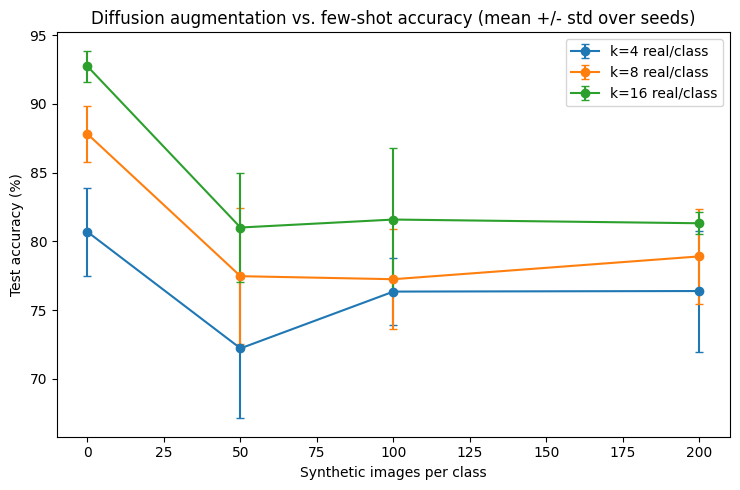

In [12]:
rows = []
for key, v in results.items():
    s, k, m = key.split("_"); rows.append({"seed": int(s[1:]), "k": int(k), "m": int(m), "acc": v * 100})
df = pd.DataFrame(rows)
summary = df.groupby(["k", "m"])["acc"].agg(["mean", "std", "count"]).round(2).reset_index()
print(summary.to_string(index=False))
print()
print((df.groupby(["k", "m"])["acc"].mean().unstack().round(2)))

# gain vs. the m=0 baseline, paired by seed
base = df[df.m == 0].set_index(["seed", "k"])["acc"]
df["gain_vs_m0"] = df.apply(lambda r: r["acc"] - base.get((r["seed"], r["k"]), np.nan), axis=1)
print("\nMean paired gain over real-only baseline (points):")
print(df[df.m > 0].groupby(["k", "m"])["gain_vs_m0"].agg(["mean", "std"]).round(2))

fig, ax = plt.subplots(figsize=(7.5, 5))
for k in KS:
    s = summary[summary.k == k]
    ax.errorbar(s["m"], s["mean"], yerr=s["std"].fillna(0), marker="o", capsize=3, label=f"k={k} real/class")
ax.set_xlabel("Synthetic images per class"); ax.set_ylabel("Test accuracy (%)")
ax.set_title("Diffusion augmentation vs. few-shot accuracy (mean +/- std over seeds)")
ax.legend(); plt.tight_layout(); plt.savefig(f"{CKPT_DIR}/augmentation_curve_v4.png", dpi=150); plt.show()

## 8. Optional - continue training if the diagnostics say the model is under-trained

In [13]:
CONTINUE_TRAINING = False     # set True only if the gate table told you to
EXTRA_STEPS = 10000

if CONTINUE_TRAINING:
    model = build_unet(); model.load_state_dict(ckpt["model"]); model.train()
    ema_sd = {k: v.clone() for k, v in ckpt["ema"].items()}
    opt = torch.optim.AdamW(model.parameters(), lr=2e-4); opt.load_state_dict(ckpt["optimizer"])
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    loader = DataLoader(train_diff_ds, batch_size=64, shuffle=True, drop_last=True, num_workers=2)
    def cycle(l):
        while True:
            for b in l: yield b
    it = cycle(loader); step = ckpt["step"]; target = step + EXTRA_STEPS
    while step < target:
        x, y_ = next(it); x, y_ = x.to(device), y_.to(device)
        y_ = torch.where(torch.rand(len(y_), device=device) < 0.1, torch.full_like(y_, NULL_CLASS), y_)
        t = torch.randint(0, diffusion.T, (x.shape[0],), device=device).long()
        opt.zero_grad()
        with torch.amp.autocast("cuda", enabled=(device == "cuda")):
            loss = diffusion.p_losses(model, x, t, y_)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        with torch.no_grad():
            for k_, v in model.state_dict().items():
                if v.dtype.is_floating_point: ema_sd[k_].mul_(0.999).add_(v.detach(), alpha=0.001)
        step += 1
        if step % 100 == 0: print(step, round(loss.item(), 4))
        if step % 1000 == 0 or step == target:
            torch.save({"model": model.state_dict(), "ema": ema_sd, "optimizer": opt.state_dict(), "step": step}, SAVE_CKPT_PATH)
    print("done; re-run Section 4 to load the new weights, then re-check the gate")